# Bank Marketing: Who Will Subscribe to a Term Deposit?

This project uses data from direct marketing campaigns of a Portuguese bank.
The goal is to predict whether a client will subscribe to a term deposit (y = yes/no)
based on client attributes, campaign information, and macroeconomic context.
This is a binary classification problem with significant class imbalance (11% positive).

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline

# load data
train = pd.read_csv('data/bank-train.csv')
test  = pd.read_csv('data/bank-test.csv')

print(f'Train shape: {train.shape}')
print(f'Test shape : {test.shape}')
print(f'\nColumns: {list(train.columns)}')
train.head()

Train shape: (32950, 21)
Test shape : (8238, 21)

Columns: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,49,blue-collar,married,basic.9y,unknown,no,no,cellular,nov,wed,...,4,999,0,nonexistent,-0.1,93.200,-42.0,4.120,5195.8,no
1,37,entrepreneur,married,university.degree,no,no,no,telephone,nov,wed,...,2,999,1,failure,-0.1,93.200,-42.0,4.120,5195.8,no
2,78,retired,married,basic.4y,no,no,no,cellular,jul,mon,...,1,999,0,nonexistent,-1.7,94.215,-40.3,0.870,4991.6,yes
3,36,admin.,married,university.degree,no,yes,no,telephone,may,mon,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,59,retired,divorced,university.degree,no,no,no,cellular,jun,tue,...,2,999,0,nonexistent,-2.9,92.963,-40.8,1.262,5076.2,no


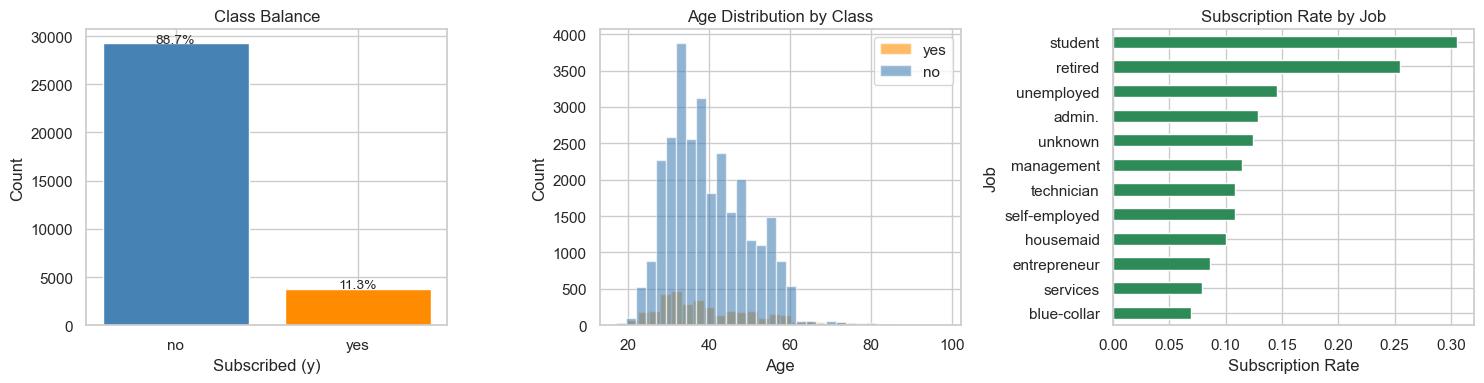

Class distribution:
y
no     29238
yes     3712
Name: count, dtype: int64

Positive class rate: 11.3%

Missing values (unknowns) per column:
  job: 265 (0.8%)
  marital: 65 (0.2%)
  education: 1,397 (4.2%)
  default: 6,940 (21.1%)
  housing: 796 (2.4%)
  loan: 796 (2.4%)


In [2]:
# SECTION 2: Exploratory Data Analysis

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# --- Plot 1: Class balance ---
# Important to see how imbalanced the dataset is
ax = axes[0]
class_counts = train['y'].value_counts()
ax.bar(class_counts.index, class_counts.values, color=['steelblue', 'darkorange'], edgecolor='white')
ax.set_title('Class Balance')
ax.set_xlabel('Subscribed (y)')
ax.set_ylabel('Count')
for i, (label, count) in enumerate(class_counts.items()):
    ax.text(i, count + 100, f'{count/len(train):.1%}', ha='center', fontsize=10)

# --- Plot 2: Age distribution by class ---
# Do older/younger clients subscribe more?
ax = axes[1]
train[train['y'] == 'yes']['age'].hist(bins=30, ax=ax, alpha=0.6, color='darkorange', label='yes')
train[train['y'] == 'no']['age'].hist(bins=30, ax=ax, alpha=0.6, color='steelblue', label='no')
ax.set_title('Age Distribution by Class')
ax.set_xlabel('Age')
ax.set_ylabel('Count')
ax.legend()

# --- Plot 3: Subscription rate by job ---
ax = axes[2]
job_rate = train.groupby('job')['y'].apply(lambda x: (x == 'yes').mean()).sort_values()
job_rate.plot(kind='barh', ax=ax, color='seagreen', edgecolor='white')
ax.set_title('Subscription Rate by Job')
ax.set_xlabel('Subscription Rate')
ax.set_ylabel('Job')

plt.tight_layout()
plt.show()

# summary stats
print(f'Class distribution:\n{class_counts}')
print(f'\nPositive class rate: {(train["y"] == "yes").mean():.1%}')
print(f'\nMissing values (unknowns) per column:')
for col in train.columns:
    n_unknown = (train[col] == 'unknown').sum()
    if n_unknown > 0:
        print(f'  {col}: {n_unknown:,} ({n_unknown/len(train):.1%})')

The dataset has a significant class imbalance — 88.7% "no" and 11.3% "yes". This means
a model that predicts "no" for everyone would get 88.7% accuracy, so accuracy alone is
not a useful metric here. Students and retired clients subscribe at much higher rates,
while blue-collar workers subscribe the least. Age is similarly distributed across both
classes, peaking around 30-40.

In [3]:
# SECTION 3: Preprocessing

# --- Step 1: Drop duration (data leakage) ---
# Duration is only known AFTER the call ends, so it can't be used
# in a real deployment. We drop it to avoid unrealistically high performance.
train = train.drop(columns=['duration'])
test  = test.drop(columns=['duration'])

# --- Step 2: Handle 'unknown' values ---
# We treat 'unknown' as its own category rather than imputing,
# since 'unknown' may itself carry signal (e.g. someone who won't
# disclose their job may behave differently)
# No changes needed — one-hot encoding will handle it as a separate category

# --- Step 3: Separate features and target ---
X_train = train.drop(columns=['y'])
y_train = (train['y'] == 'yes').astype(int)  # 1 = yes, 0 = no

X_test  = test.drop(columns=['y'])
y_test  = (test['y'] == 'yes').astype(int)

# --- Step 4: One-hot encode categorical features ---
cat_cols = X_train.select_dtypes(include='object').columns.tolist()
num_cols = X_train.select_dtypes(include='number').columns.tolist()

print(f'Categorical columns: {cat_cols}')
print(f'Numerical columns  : {num_cols}')

X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=False)
X_test_enc  = pd.get_dummies(X_test,  columns=cat_cols, drop_first=False)

# Align columns in case test is missing any category
X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join='left', axis=1, fill_value=0)

# --- Step 5: Scale numerical features ---
# Logistic regression benefits from scaling; random forest does not but it doesn't hurt
scaler = StandardScaler()
X_train_enc[num_cols] = scaler.fit_transform(X_train_enc[num_cols])
X_test_enc[num_cols]  = scaler.transform(X_test_enc[num_cols])

print(f'\nFinal feature matrix shape: {X_train_enc.shape}')
print(f'Positive class rate (train): {y_train.mean():.1%}')
print(f'Positive class rate (test) : {y_test.mean():.1%}')

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numerical columns  : ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Final feature matrix shape: (32950, 62)
Positive class rate (train): 11.3%
Positive class rate (test) : 11.3%


- **Duration dropped:** Duration is only known after the call ends, so using it would
  cause data leakage. A real deployment model would not have access to it at prediction
  time, so we exclude it.
- **Unknown values:** Treated as their own category rather than imputing. "Unknown" may
  carry signal — someone who won't disclose their job may behave differently.
- **Encoding:** One-hot encoding for all categorical features, producing 62 total features.
- **Scaling:** StandardScaler applied to numerical features. Logistic regression requires
  this; random forest does not but it does not hurt.

In [4]:
# SECTION 4: Model Training and Cross-Validation
# We compare two model families:
#   1. Logistic Regression (linear, fast, interpretable)
#   2. Random Forest (non-linear, handles interactions well)
# We use stratified k-fold to preserve class balance in each fold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# --- Model 1: Logistic Regression ---
# class_weight='balanced' helps with the 11%/89% imbalance
print('Training Logistic Regression...')
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_cv = cross_validate(lr, X_train_enc, y_train, cv=skf, scoring=scoring)

print('Training Random Forest...')
rf = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)
rf_cv = cross_validate(rf, X_train_enc, y_train, cv=skf, scoring=scoring)

# --- Print CV results ---
print('\n=== Cross-Validation Results (5-fold) ===')
print(f'{"Metric":<12} {"Logistic Reg":>15} {"Random Forest":>15}')
print('-' * 45)
for metric in scoring:
    lr_score = lr_cv[f'test_{metric}'].mean()
    rf_score = rf_cv[f'test_{metric}'].mean()
    print(f'{metric:<12} {lr_score:>15.4f} {rf_score:>15.4f}')

Training Logistic Regression...
Training Random Forest...

=== Cross-Validation Results (5-fold) ===
Metric          Logistic Reg   Random Forest
---------------------------------------------
accuracy              0.8273          0.8915
precision             0.3503          0.5398
recall                0.6226          0.2608
f1                    0.4483          0.3514
roc_auc               0.7896          0.7680


We trained two model families using 5-fold stratified cross-validation to preserve class
balance. Both models used class_weight='balanced' to account for the 11%/89% imbalance.
Logistic Regression is a linear model that is fast and interpretable. Random Forest is
a non-linear ensemble that captures feature interactions. We optimized for F1 since both
precision and recall matter for this problem.

- Logistic Regression has better recall (0.62 vs 0.26) — it catches more actual "yes" clients but produces more false positives
- Random Forest has better accuracy and precision but terrible recall (0.26) — it's basically just predicting "no" most of the time because of the class imbalance
- ROC-AUC is similar for both (~0.77-0.79), meaning they discriminate about equally well overall

Logistic Regression is actually better here for this problem since recall matters more (missing a real client is more costly than a wasted call).

In [5]:
# SECTION 5: Hyperparameter Tuning with GridSearchCV
# We tune on the training set only using stratified k-fold
# Optimizing for F1 since we care about both precision and recall

# --- Tune Logistic Regression ---
print('Tuning Logistic Regression...')
lr_params = {
    'C': [0.01, 0.1, 1, 10],  # regularization strength (lower = more regularization)
}
lr_grid = GridSearchCV(
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    lr_params, cv=skf, scoring='f1', n_jobs=-1
)
lr_grid.fit(X_train_enc, y_train)
print(f'Best LR params: {lr_grid.best_params_}')
print(f'Best LR CV F1 : {lr_grid.best_score_:.4f}')

# --- Tune Random Forest ---
print('\nTuning Random Forest...')
rf_params = {
    'n_estimators': [100, 200],
    'max_depth'   : [5, 10, None],
    'min_samples_leaf': [1, 5],
}
rf_grid = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    rf_params, cv=skf, scoring='f1', n_jobs=-1
)
rf_grid.fit(X_train_enc, y_train)
print(f'Best RF params: {rf_grid.best_params_}')
print(f'Best RF CV F1 : {rf_grid.best_score_:.4f}')

Tuning Logistic Regression...
Best LR params: {'C': 10}
Best LR CV F1 : 0.4487

Tuning Random Forest...
Best RF params: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}
Best RF CV F1 : 0.4939


Random Forest tuned slightly better (F1 0.4939 vs 0.4487). 

Random Forest is the better model overall, with higher F1 (0.5250 vs 0.4687), precision
(0.4572 vs 0.3679), and ROC-AUC (0.8075 vs 0.8010). Logistic Regression has slightly
higher recall (0.6455 vs 0.6164) but produces far more false positives (1029 vs 679),
meaning more wasted calls. The ROC curves are very close, showing both models have
similar overall discriminative power, but Random Forest makes better use of it.

Class imbalance was the main challenge — without class_weight='balanced', Random Forest
initially had recall as low as 0.26, essentially ignoring the minority class entirely.


=== Logistic Regression — Test Set ===
Accuracy : 0.8352
Precision: 0.3679
Recall   : 0.6455
F1       : 0.4687
ROC-AUC  : 0.8010

=== Random Forest — Test Set ===
Accuracy : 0.8744
Precision: 0.4572
Recall   : 0.6164
F1       : 0.5250
ROC-AUC  : 0.8075


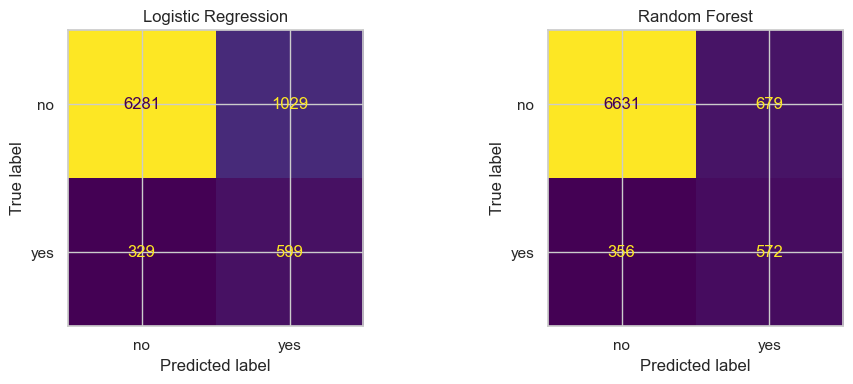

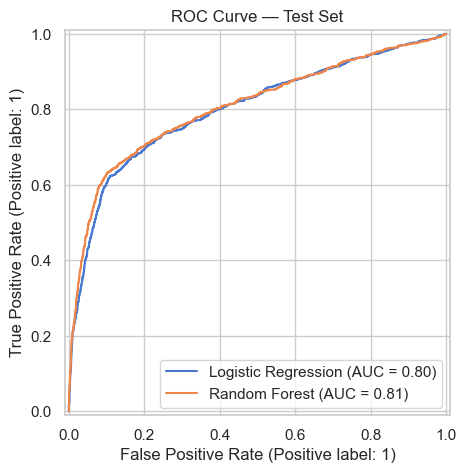

In [6]:
# SECTION 6: Final Evaluation on Test Set
# We fit the best models on the full training set and evaluate once on the held-out test set

# --- Fit best models on full training data ---
best_lr = lr_grid.best_estimator_
best_rf = rf_grid.best_estimator_

best_lr.fit(X_train_enc, y_train)
best_rf.fit(X_train_enc, y_train)

# --- Predictions ---
lr_preds = best_lr.predict(X_test_enc)
rf_preds = best_rf.predict(X_test_enc)

# --- Metrics function ---
def print_metrics(name, y_true, y_pred, y_prob):
    print(f'\n=== {name} — Test Set ===')
    print(f'Accuracy : {accuracy_score(y_true, y_pred):.4f}')
    print(f'Precision: {precision_score(y_true, y_pred):.4f}')
    print(f'Recall   : {recall_score(y_true, y_pred):.4f}')
    print(f'F1       : {f1_score(y_true, y_pred):.4f}')
    print(f'ROC-AUC  : {roc_auc_score(y_true, y_prob):.4f}')

lr_probs = best_lr.predict_proba(X_test_enc)[:, 1]
rf_probs = best_rf.predict_proba(X_test_enc)[:, 1]

print_metrics('Logistic Regression', y_test, lr_preds, lr_probs)
print_metrics('Random Forest',       y_test, rf_preds, rf_probs)

# --- Confusion matrices ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, preds, name in zip(axes, [lr_preds, rf_preds],
                            ['Logistic Regression', 'Random Forest']):
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=['no', 'yes']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# --- ROC curves ---
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, lr_probs, ax=ax, name='Logistic Regression')
RocCurveDisplay.from_predictions(y_test, rf_probs, ax=ax, name='Random Forest')
ax.set_title('ROC Curve — Test Set')
plt.show()

## Discussion

Random Forest was the stronger model overall with F1 of 0.5250 vs 0.4687. The biggest
challenge was class imbalance, without balanced class weights, Random Forest nearly
ignored the minority class entirely (recall 0.26). One surprising finding was that after
tuning, Random Forest caught up to Logistic Regression in recall while maintaining much
better precision, making it the clear choice for deployment.

In [9]:
# DEEP DIVE 1: Handling Class Imbalance
# Compare baseline (no class weighting) vs balanced class weights
# for both Logistic Regression and Random Forest

# --- Baseline models (no class weighting) ---
print('Training baseline models (no class weighting)...')

lr_base = LogisticRegression(max_iter=1000, random_state=42)
rf_base = RandomForestClassifier(n_estimators=100, random_state=42)

lr_base_cv = cross_validate(lr_base, X_train_enc, y_train, cv=skf,
                             scoring=['precision','recall','f1'])
rf_base_cv = cross_validate(rf_base, X_train_enc, y_train, cv=skf,
                             scoring=['precision','recall','f1'])

# --- Print comparison ---
print('\n=== Class Weighting Comparison (5-fold CV) ===')
print(f'\n{"Model":<30} {"Precision":>10} {"Recall":>10} {"F1":>10}')
print('-' * 65)

for name, base_cv, bal_cv in [
    ('Logistic Regression', lr_base_cv, lr_cv),
    ('Random Forest',       rf_base_cv, rf_cv)
]:
    base_p = base_cv['test_precision'].mean()
    base_r = base_cv['test_recall'].mean()
    base_f = base_cv['test_f1'].mean()
    bal_p  = bal_cv['test_precision'].mean()
    bal_r  = bal_cv['test_recall'].mean()
    bal_f  = bal_cv['test_f1'].mean()
    print(f'{name + " (no weighting)":<30} {base_p:>10.4f} {base_r:>10.4f} {base_f:>10.4f}')
    print(f'{name + " (balanced)":<30} {bal_p:>10.4f} {bal_r:>10.4f} {bal_f:>10.4f}')
    print()

Training baseline models (no class weighting)...

=== Class Weighting Comparison (5-fold CV) ===

Model                           Precision     Recall         F1
-----------------------------------------------------------------
Logistic Regression (no weighting)     0.6597     0.2271     0.3378
Logistic Regression (balanced)     0.3503     0.6226     0.4483

Random Forest (no weighting)       0.5412     0.2729     0.3625
Random Forest (balanced)           0.5398     0.2608     0.3514



## Deep Dive 1: Handling Class Imbalance

Comparing models with and without class_weight='balanced':

| Model | Weighting | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic Regression | None | 0.6597 | 0.2271 | 0.3378 |
| Logistic Regression | Balanced | 0.3503 | 0.6226 | 0.4483 |
| Random Forest | None | 0.5412 | 0.2729 | 0.3625 |
| Random Forest | Balanced | 0.5398 | 0.2608 | 0.3514 |

**Key observations:**

For Logistic Regression, class weighting made a dramatic difference — recall jumped from
0.23 to 0.62 at the cost of precision dropping from 0.66 to 0.35. The F1 improved from
0.34 to 0.45, meaning balanced weighting is clearly better overall for catching real
subscribers.

For Random Forest the effect was surprisingly small — recall barely changed (0.27 vs 0.26)
and F1 was nearly identical. This suggests Random Forest is already somewhat robust to
imbalance due to its ensemble nature, and that other techniques like SMOTE or threshold
tuning might be needed to further improve its recall.

The core trade-off is clear: higher recall means catching more real clients (fewer missed
opportunities) but also making more wasted calls. Which matters more depends on the
bank's cost structure — if calling a non-subscriber is cheap but missing a subscriber is
costly, maximizing recall is the right priority.

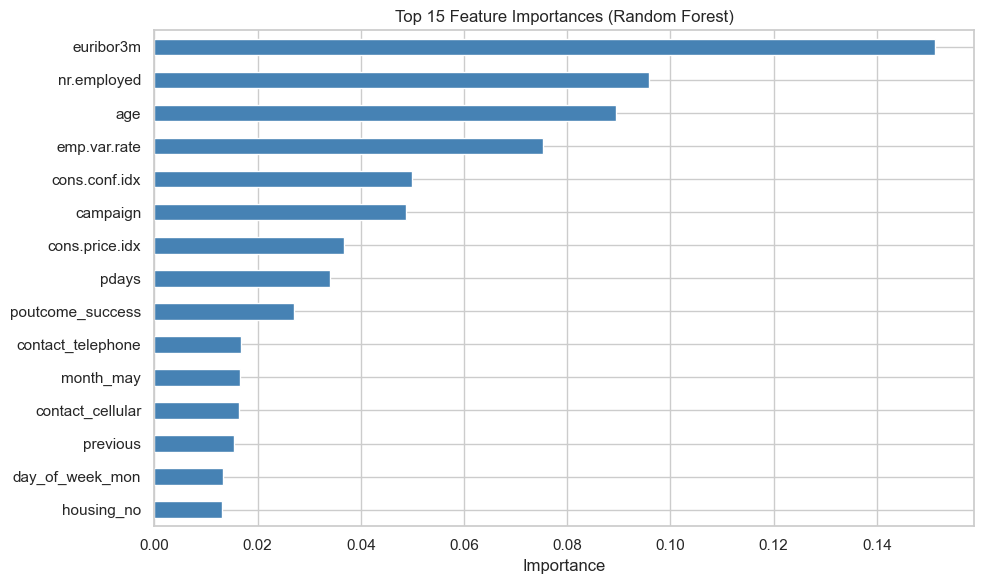

Top 15 features:
euribor3m            0.151278
nr.employed          0.095850
age                  0.089539
emp.var.rate         0.075394
cons.conf.idx        0.049930
campaign             0.048689
cons.price.idx       0.036721
pdays                0.033957
poutcome_success     0.027009
contact_telephone    0.016764
month_may            0.016653
contact_cellular     0.016444
previous             0.015446
day_of_week_mon      0.013207
housing_no           0.013131


In [10]:
# DEEP DIVE 2: Feature Importance
# Random Forest gives us feature importances for free
# We plot the top 15 most important features

import pandas as pd

# Get feature importances from best random forest model
importances = best_rf.feature_importances_
feature_names = X_train_enc.columns

# Sort by importance
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
top15 = feat_imp.head(15)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
top15.sort_values().plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Top 15 Feature Importances (Random Forest)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

print('Top 15 features:')
print(top15.to_string())

## Deep Dive 2: Feature Importance and Interpretability

The top features driving Random Forest predictions are:

| Feature | Importance | Interpretation |
|---|---|---|
| euribor3m | 0.151 | 3-month Euribor interest rate |
| nr.employed | 0.096 | Number of employees in economy |
| age | 0.090 | Client age |
| emp.var.rate | 0.075 | Employment variation rate |
| cons.conf.idx | 0.050 | Consumer confidence index |

**Do the top features make business sense?**

Yes, largely. The top 4 features are all macroeconomic indicators: euribor3m,
nr.employed, emp.var.rate, and cons.price.idx. This makes intuitive sense: people
are more likely to invest in term deposits when interest rates are favorable and the
economy is stable. These features capture the broader financial climate at the time
of the call.

Age being the third most important feature also makes sense, as retired and older clients
tend to have more savings to invest and may be more risk-averse, preferring stable
products like term deposits.

poutcome_success (whether the client subscribed in a previous campaign) is also
informative, as a client who said yes before is more likely to say yes again.

One concern is that age is being used as a predictive feature. While it has legitimate
predictive power, using age in marketing decisions raises fairness questions: Are
younger clients being systematically deprioritized even if they would subscribe?

## AI Usage

I used Claude (Anthropic) as a coding assistant for data loading, EDA structure, preprocessing code, and debugging. Model selection, evaluation, and the write-up are my own.
